# Couette prediction comparison (multi-model)

Load **several** trained pressure→velocity checkpoints from S3, generate predictions for each on the validation set, and compare them all against the DNS ground truth on the same axes.

Metrics (DNS target + one curve per model):
1. Mean & std velocity per component along y
2. MSE scalar + along y
3. 2D energy spectrum E(k) per |k| annulus (+ relative error)
4. RMS fluctuations & Reynolds stress along y
5. PDF of velocity fluctuations

To change which models are compared, edit the `CHECKPOINTS` list in the "load models" cell.


In [1]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn

device = "cuda"
keys = 'u', 'v', 'w', 'p_total'
comp_labels = ['u_x', 'u_y', 'u_z']

def extract(real, keys):
    with h5py.File("/data1/dataToYouri/couette_dns_ml_f32.h5", 'r') as f:
        data = []
        for k in keys:
            data.append(np.array(f[real][k]))
        return np.stack(data, axis=1)

realizations = ['R13', 'R14', 'R15', 'R18', 'R19', 'R21', 'R22', 'R23', 'R26', 'R28', 'R3', 'R4', 'R5']
samplings = {real: np.s_[:-1:5000 // 300] if real in ["R3", "R4", "R5"] else np.s_[:] for real in realizations}

raw_d = {real: extract(real, keys)[samplings[real]] for real in realizations}
all_data = np.concatenate(list(raw_d.values()), axis=0)

val_realizations = ["R18", "R5"]
test_realizations = ["R3", "R14"]
train_realizations = [real for real in realizations if real not in val_realizations + test_realizations]
val_npds = np.concatenate([raw_d[r] for r in val_realizations])

print("val data shape:", val_npds.shape)

with h5py.File("/data1/dataToYouri/couette_dns_ml_f32.h5", 'r') as f:
    y = np.array(f["y"])
    x = np.array(f["x"])
    z = np.array(f["z"])

print("y shape:", y.shape)

# ground truth in physical units (shared by all models)
target_phys = val_npds[:, :3, :, :, :].astype(np.float32)
print("target_phys shape:", target_phys.shape)


val data shape: (600, 4, 24, 33, 24)
y shape: (33,)
target_phys shape: (600, 3, 24, 33, 24)


In [2]:
# =========================================================================
# Load several checkpoints from S3 and generate predictions for each
# =========================================================================
import s3fs, io

S3_BUCKET = "simulations"
S3_ENDPOINT = "http://localhost:8333"
fs = s3fs.S3FileSystem(profile='default', client_kwargs={'endpoint_url': S3_ENDPOINT})

# --- the set of models to compare ---
# each entry: (display_name, s3_key_relative_to_bucket, widen)
# widen must match how the checkpoint was trained (0 or 1)
CHECKPOINTS = [
    ("lw32_c32_b5_w0", "flow_models/couette/width-study_lw32_c32_b5_w0/final.pt",   0),
    ("lw32_c32_b5_w1", "flow_models/couette/width-study_lw32_c32_b5_w1/final.pt",   1),
    ("lw32_c32_b10_w0", "flow_models/couette/width-study_lw32_c32_b10_w0/final.pt", 0),
    ("lw32_c64_b5_w0", "flow_models/couette/width-study_lw32_c64_b5_w0/final.pt",   0),
]

# --- M4 architecture (same as framework_2.ipynb) ---
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding="same"),
            nn.SiLU(),
            nn.Conv3d(out_ch, out_ch, 3, padding="same"),
            nn.SiLU(),
        )
    def forward(self, x):
        return self.conv(x)

class M4(nn.Module):
    def __init__(self, lift_width=32, c3d=32, n_blocks=5, widen=0):
        super().__init__()
        self.D = 33
        self.c3d = c3d
        self.xd, self.zd = 24, 24
        self.pressure_encoder = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding="same"), nn.SiLU(),
            nn.Conv2d(8, 32, 3, padding="same"), nn.SiLU(),
        )
        in_lift = 32
        if widen > 0:
            self.pre_widen = nn.Sequential(nn.Conv2d(32, widen, 3, padding="same"), nn.SiLU())
            in_lift = widen
        self.lift = nn.Conv2d(in_lift, self.D * lift_width, 3, padding="same")
        self.lift_proj = (nn.Conv3d(lift_width, c3d, 1) if lift_width != c3d else nn.Identity())
        self.conv_blocks = nn.Sequential(*[ConvBlock(c3d, c3d) for _ in range(n_blocks)])
        self.output = nn.Conv3d(c3d, 3, 3, padding="same")

    def forward(self, pressure):
        x = self.pressure_encoder(pressure)
        if hasattr(self, "pre_widen"):
            x = self.pre_widen(x)
        x = self.lift(x)
        x = x.reshape(-1, self.lift.out_channels // self.D, self.xd, self.D, self.zd)
        x = self.lift_proj(x)
        x = self.conv_blocks(x)
        x = self.output(x)
        return x

# --- normalization + dataset (shared) ---
normalization_axes = (0, 2, 4)
all_data_mean = all_data.mean(normalization_axes, keepdims=True)
all_data_std = all_data.std(normalization_axes, keepdims=True) + 1e-10
all_data_mean_gpu = torch.from_numpy(all_data_mean).to(device)
all_data_std_gpu = torch.from_numpy(all_data_std).to(device)

def normalize(data):
    return (data - all_data_mean) / all_data_std

def unnormalize_velocity_gpu(data):
    return (data * all_data_std_gpu[:, :3]) + all_data_mean_gpu[:, :3]

class ValDS(Dataset):
    def __init__(self, d):
        self.x = torch.from_numpy(d[:, 3:, :, 0, :]).float().to(device)
        self.y = torch.from_numpy(d[:, :3, :, :, :]).float().to(device)
    def __len__(self):
        return self.x.shape[0]
    def __getitem__(self, i):
        return self.x[i], self.y[i]

val_ds = ValDS(normalize(val_npds))
batch_size = 4
val_dl = DataLoader(val_ds, batch_size=batch_size, shuffle=False, drop_last=True)
print(f"val dataset: {len(val_ds)} samples, {len(val_dl)} batches\n")

# --- helper to predict + unnormalize ---
@torch.no_grad()
def predict_phys(model, ds):
    model.eval()
    out = []
    for xb, yb in ds:
        out.append(model(xb))
    pred_norm = torch.cat(out, dim=0)
    return unnormalize_velocity_gpu(pred_norm).cpu().numpy()

# --- load each checkpoint and predict ---
models = {}      # name -> dict(pred_phys, n_params, cfg)
for name, key, widen in CHECKPOINTS:
    try:
        buf = fs.cat_file(f"{S3_BUCKET}/{key}")
        ckpt = torch.load(io.BytesIO(buf), map_location="cpu")
        cfg = ckpt["config"]
        model = M4(lift_width=cfg["lift_width"], c3d=cfg["c3d"],
                   n_blocks=cfg["n_blocks"], widen=widen).to(device)
        model.load_state_dict(ckpt["model_state_dict"])
        model.eval()
        n_params = sum(p.numel() for p in model.parameters())
        pred = predict_phys(model, val_dl)
        models[name] = dict(pred_phys=pred, n_params=n_params, cfg=cfg, widen=widen)
        print(f"[OK]   {name}: {n_params/1e6:.2f}M params  (lw={cfg['lift_width']} c={cfg['c3d']} "
              f"b={cfg['n_blocks']} w={widen})  pred range [{pred.min():.3f}, {pred.max():.3f}]")
        del model
    except Exception as e:
        print(f"[SKIP] {name}: {type(e).__name__}: {e}")

model_names = list(models.keys())
print(f"\nloaded {len(model_names)}/{len(CHECKPOINTS)} models: {model_names}")

# --- a stable color per model (DNS is always black) ---
cmap_models = plt.get_cmap("tab10")
MODEL_COLORS = {name: cmap_models(i % 10) for i, name in enumerate(model_names)}
DNS_COLOR = "black"


val dataset: 600 samples, 150 batches

[OK]   lw32_c32_b5_w0: 0.59M params  (lw=32 c=32 b=5 w=0)  pred range [-0.943, 0.958]
[OK]   lw32_c32_b5_w1: 0.29M params  (lw=32 c=32 b=5 w=1)  pred range [-0.999, 0.991]
[OK]   lw32_c32_b10_w0: 0.86M params  (lw=32 c=32 b=10 w=0)  pred range [-0.961, 1.085]
[OK]   lw32_c64_b5_w0: 1.42M params  (lw=32 c=64 b=5 w=0)  pred range [-1.006, 1.007]

loaded 4/4 models: ['lw32_c32_b5_w0', 'lw32_c32_b5_w1', 'lw32_c32_b10_w0', 'lw32_c64_b5_w0']


mean |profile - DNS| per component (lower is better):
      lw32_c32_b5_w0: max|Δmean|=1.444e-02   max|Δstd|=4.346e-02
      lw32_c32_b5_w1: max|Δmean|=1.884e-02   max|Δstd|=1.558e-02
     lw32_c32_b10_w0: max|Δmean|=1.616e-02   max|Δstd|=1.133e-02
      lw32_c64_b5_w0: max|Δmean|=8.924e-03   max|Δstd|=4.526e-02


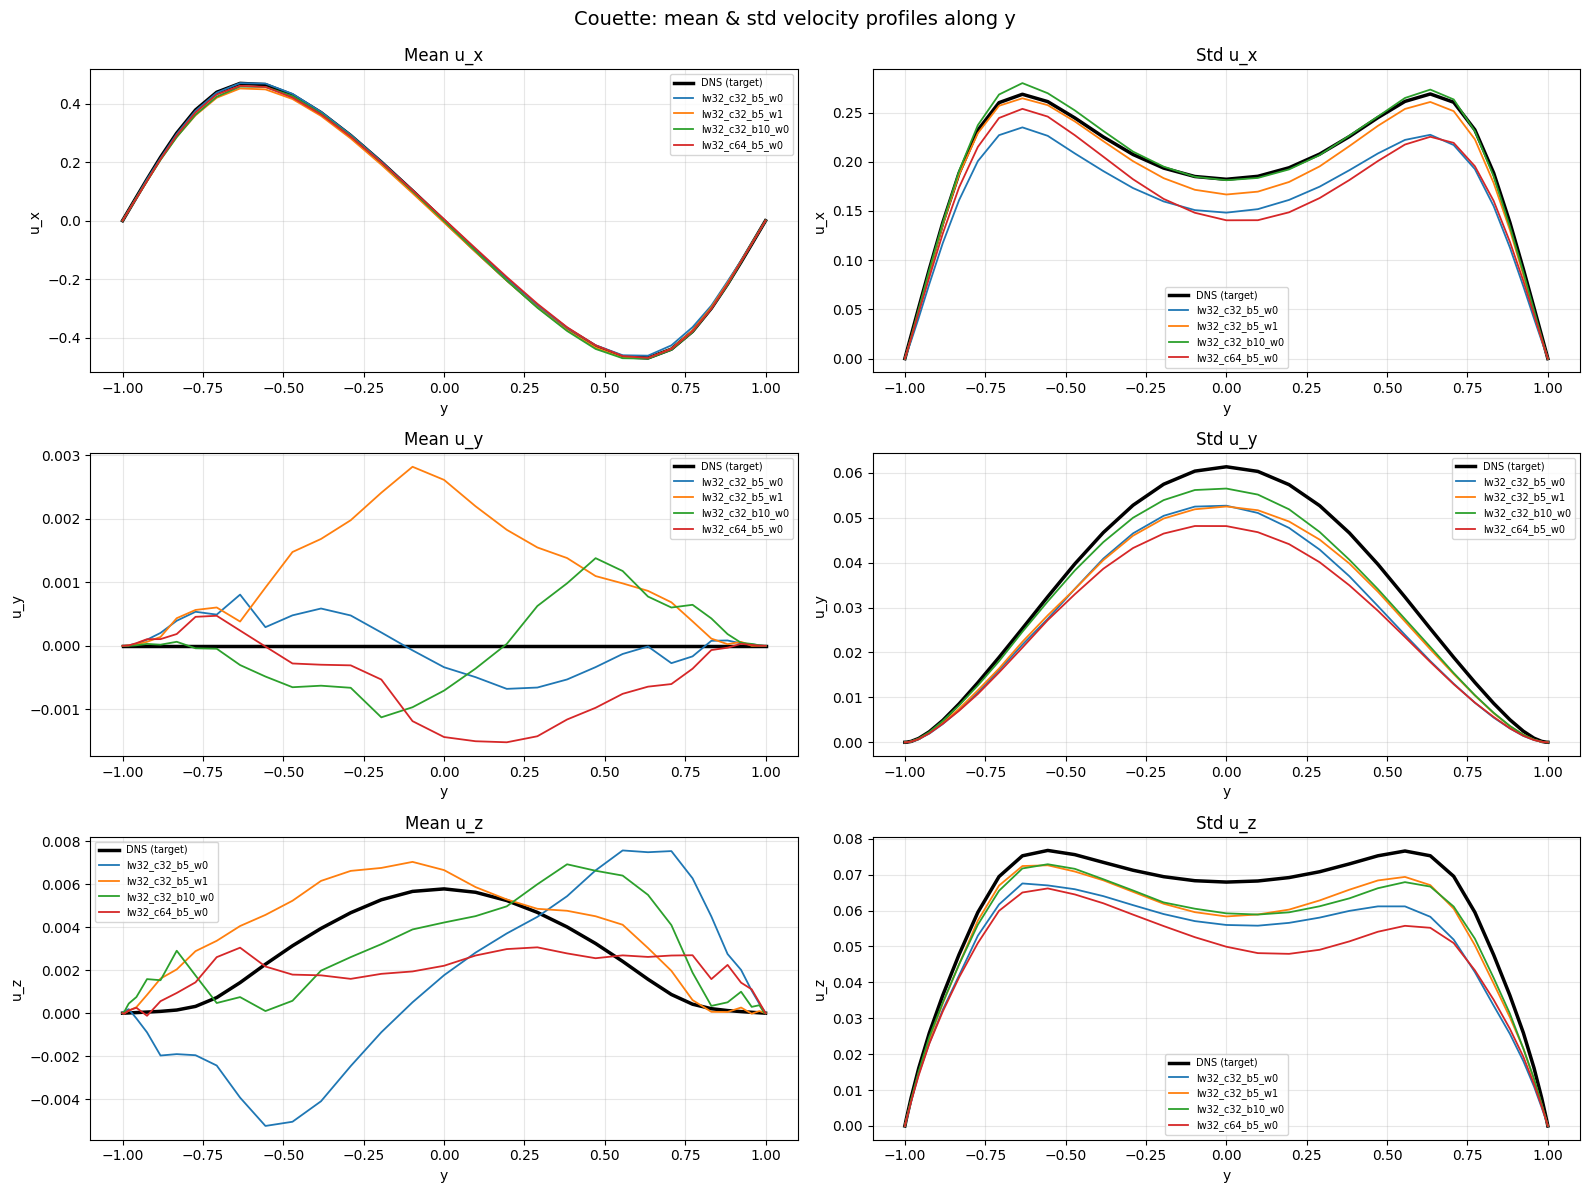

In [3]:
# =========================================================================
# Mean & std velocity per component along y  (DNS + each model)
# =========================================================================
mean_tgt = target_phys.mean(axis=(0, 2, 4))    # (3, 33)
std_tgt = target_phys.std(axis=(0, 2, 4))      # (3, 33)

fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle("Couette: mean & std velocity profiles along y", fontsize=14, y=0.99)

for c, lab in enumerate(comp_labels):
    # mean
    ax = axes[c, 0]
    ax.plot(y, mean_tgt[c], DNS_COLOR, lw=2.5, label='DNS (target)')
    for name in model_names:
        mean_m = models[name]["pred_phys"].mean(axis=(0, 2, 4))
        ax.plot(y, mean_m[c], color=MODEL_COLORS[name], lw=1.3, label=name)
    ax.set_title(f'Mean {lab}')
    ax.set_xlabel('y'); ax.set_ylabel(lab)
    ax.legend(fontsize=7); ax.grid(alpha=0.3)

    # std
    ax = axes[c, 1]
    ax.plot(y, std_tgt[c], DNS_COLOR, lw=2.5, label='DNS (target)')
    for name in model_names:
        std_m = models[name]["pred_phys"].std(axis=(0, 2, 4))
        ax.plot(y, std_m[c], color=MODEL_COLORS[name], lw=1.3, label=name)
    ax.set_title(f'Std {lab}')
    ax.set_xlabel('y'); ax.set_ylabel(lab)
    ax.legend(fontsize=7); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# --- summary table of mean/std RMS deviation from DNS ---
print("mean |profile - DNS| per component (lower is better):")
for name in model_names:
    p = models[name]["pred_phys"]
    dmean = np.abs(p.mean(axis=(0,2,4)) - mean_tgt).max()
    dstd  = np.abs(p.std(axis=(0,2,4))  - std_tgt).max()
    print(f"  {name:>18}: max|Δmean|={dmean:.3e}   max|Δstd|={dstd:.3e}")


Global MSE per model:
      lw32_c32_b5_w0: 2.514e-03
      lw32_c32_b5_w1: 2.734e-03
     lw32_c32_b10_w0: 1.314e-03
      lw32_c64_b5_w0: 2.393e-03


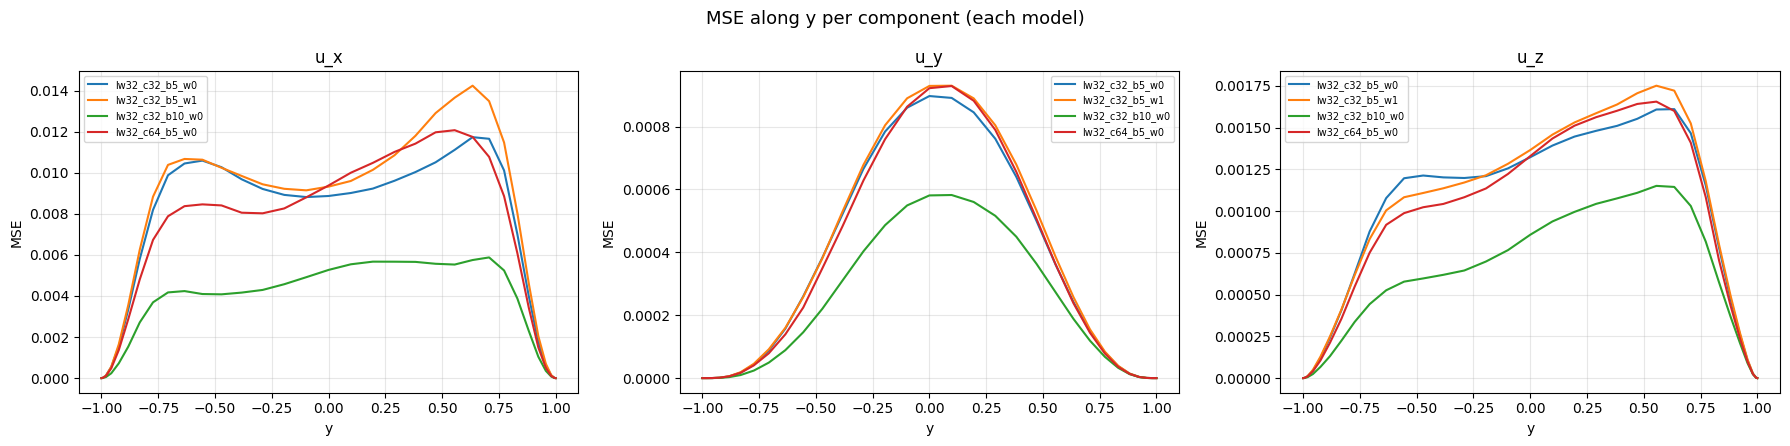

In [4]:
# =========================================================================
# MSE scalar + along y  (each model)
# =========================================================================
print("Global MSE per model:")
for name in model_names:
    p = models[name]["pred_phys"]
    mse = float(((p - target_phys) ** 2).mean())
    print(f"  {name:>18}: {mse:.3e}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
fig.suptitle("MSE along y per component (each model)", fontsize=13)
for c, lab in enumerate(comp_labels):
    ax = axes[c]
    for name in model_names:
        p = models[name]["pred_phys"]
        mse_y = ((p - target_phys) ** 2).mean(axis=(0, 2, 4))
        ax.plot(y, mse_y[c], color=MODEL_COLORS[name], lw=1.5, label=name)
    ax.set_title(f'{lab}')
    ax.set_xlabel('y'); ax.set_ylabel('MSE')
    ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


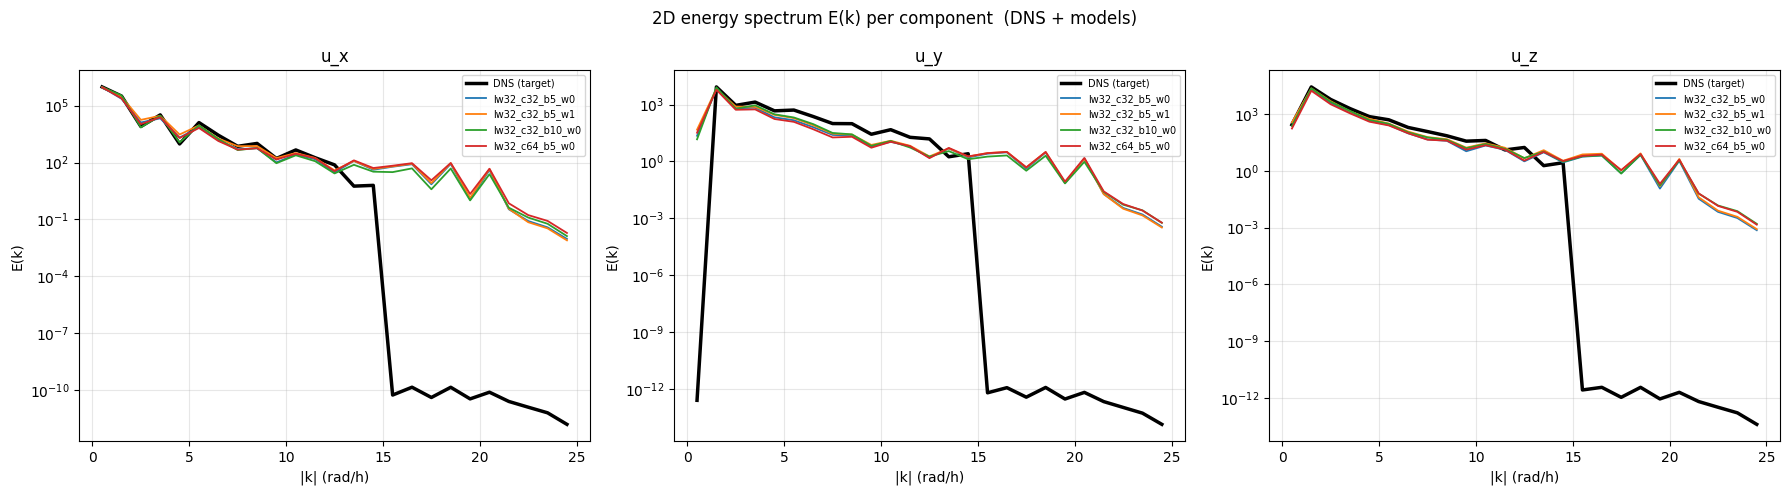

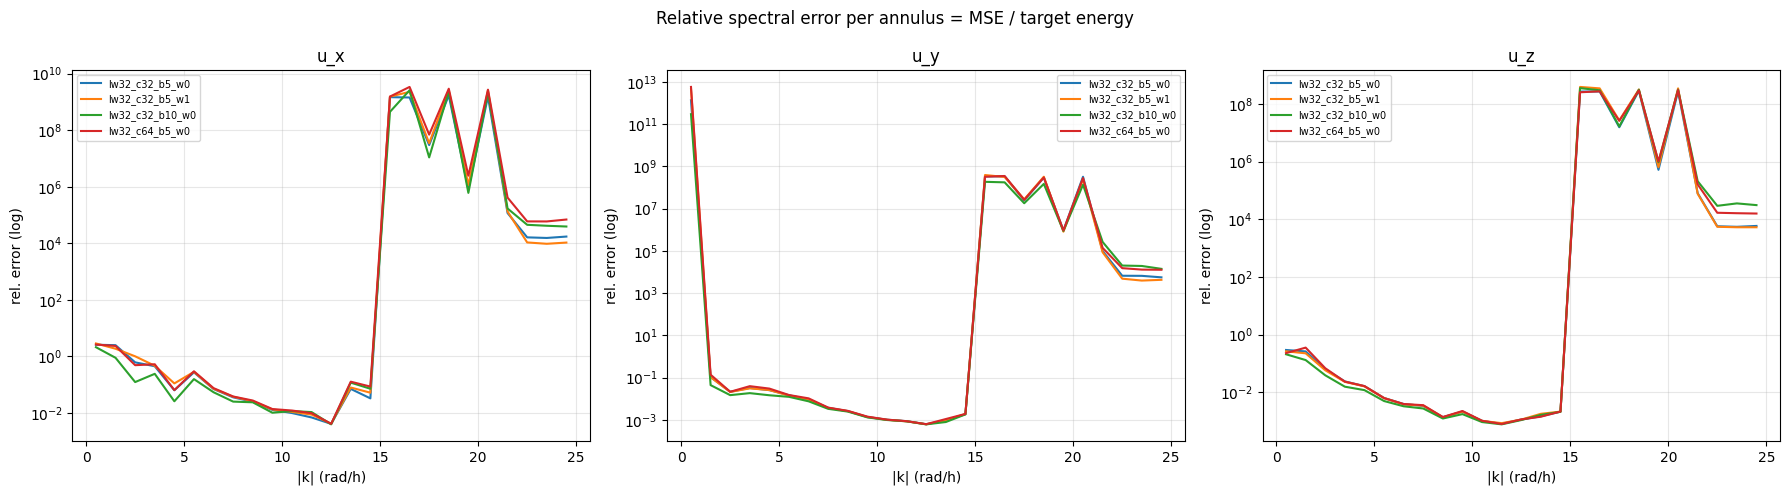

In [5]:
# =========================================================================
# 2D energy spectrum E(k) per component — DNS + each model
# =========================================================================
Lx, Lz = 1.755 * np.pi, 1.2 * np.pi
nx, nyy, nz = 24, 33, 24
kx = np.fft.fftfreq(nx, d=Lx / nx) * 2 * np.pi
kz = np.fft.fftfreq(nz, d=Lz / nz) * 2 * np.pi
KX, KZ = np.meshgrid(kx, kz, indexing="xy")
K2c = np.sqrt(KX**2 + KZ**2)

def energy_spectrum(field, comp):
    F = np.fft.fft2(field[:, comp], axes=(1, 3))
    return (np.abs(F)**2) / (nx*nz)

# precompute DNS spectrum
tgt_spec = np.stack([energy_spectrum(target_phys, c) for c in range(3)])  # (3,N,X,Y,Z)

dk = 1.0
k_edges = np.arange(0.0, K2c.max() + dk, dk)
k_centers = 0.5 * (k_edges[:-1] + k_edges[1:])
n_bins = len(k_centers)
ann_masks = [(K2c >= k_edges[i]) & (K2c < k_edges[i+1]) for i in range(n_bins)]

# DNS E(k)
tgt_E = np.zeros((n_bins, 3))
for c in range(3):
    for i, m in enumerate(ann_masks):
        tgt_E[i, c] = (tgt_spec[c] * m[None, :, None, :]).sum(axis=(1, 3)).sum()

nonempty = np.array([m.sum() > 0 for m in ann_masks])
k_centers_p = k_centers[nonempty]
tgt_E_p = tgt_E[nonempty]

# each model E(k)
model_E = {}
for name in model_names:
    p = models[name]["pred_phys"]
    spec = np.stack([energy_spectrum(p, c) for c in range(3)])
    E = np.zeros((n_bins, 3))
    for c in range(3):
        for i, m in enumerate(ann_masks):
            E[i, c] = (spec[c] * m[None, :, None, :]).sum(axis=(1, 3)).sum()
    model_E[name] = E[nonempty]
    del spec

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("2D energy spectrum E(k) per component  (DNS + models)", fontsize=12)
for c, lab in enumerate(comp_labels):
    ax = axes[c]
    ax.semilogy(k_centers_p, tgt_E_p[:, c], DNS_COLOR, lw=2.5, label='DNS (target)')
    for name in model_names:
        ax.semilogy(k_centers_p, model_E[name][:, c], color=MODEL_COLORS[name], lw=1.3, label=name)
    ax.set_title(f'{lab}')
    ax.set_xlabel('|k| (rad/h)'); ax.set_ylabel('E(k)')
    ax.grid(alpha=0.3, which='both'); ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# =========================================================================
# Relative spectral error per annulus (each model): MSE / target energy
# =========================================================================
model_rel_err = {}
for name in model_names:
    p = models[name]["pred_phys"]
    spec = np.stack([energy_spectrum(p, c) for c in range(3)])
    mse_E = np.zeros((n_bins, 3))
    for c in range(3):
        for i, m in enumerate(ann_masks):
            mse_E[i, c] = (((spec[c] - tgt_spec[c]) * m[None, :, None, :])**2).sum()
    del spec
    with np.errstate(divide='ignore', invalid='ignore'):
        rel = np.where(tgt_E_p > 0, mse_E[nonempty] / np.maximum(tgt_E_p, 1e-300), np.nan)
    model_rel_err[name] = rel

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Relative spectral error per annulus = MSE / target energy", fontsize=12)
for c, lab in enumerate(comp_labels):
    ax = axes[c]
    for name in model_names:
        ax.semilogy(k_centers_p, model_rel_err[name][:, c], color=MODEL_COLORS[name], lw=1.5, label=name)
    ax.set_title(f'{lab}')
    ax.set_xlabel('|k| (rad/h)'); ax.set_ylabel('rel. error (log)')
    ax.grid(alpha=0.3, which='both'); ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


max |profile - DNS| per model:
      lw32_c32_b5_w0: maxΔRMS=4.346e-02   maxΔRstress=7.171e+03
      lw32_c32_b5_w1: maxΔRMS=1.558e-02   maxΔRstress=1.910e+03
     lw32_c32_b10_w0: maxΔRMS=1.133e-02   maxΔRstress=2.148e+03
      lw32_c64_b5_w0: maxΔRMS=4.526e-02   maxΔRstress=7.432e+03


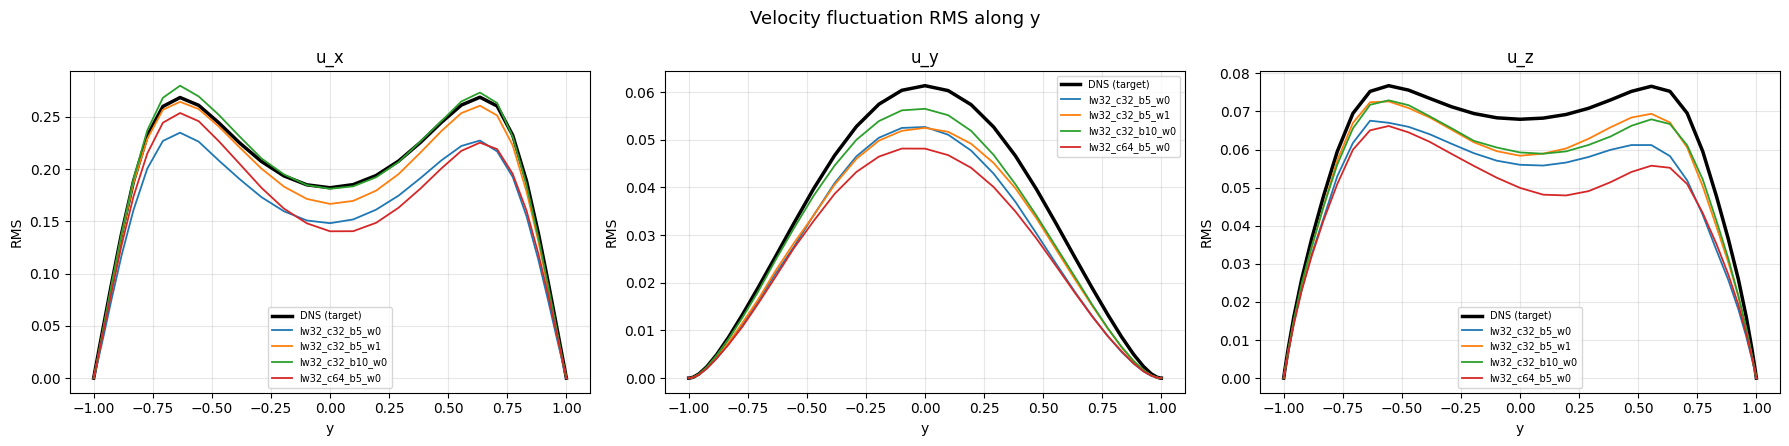

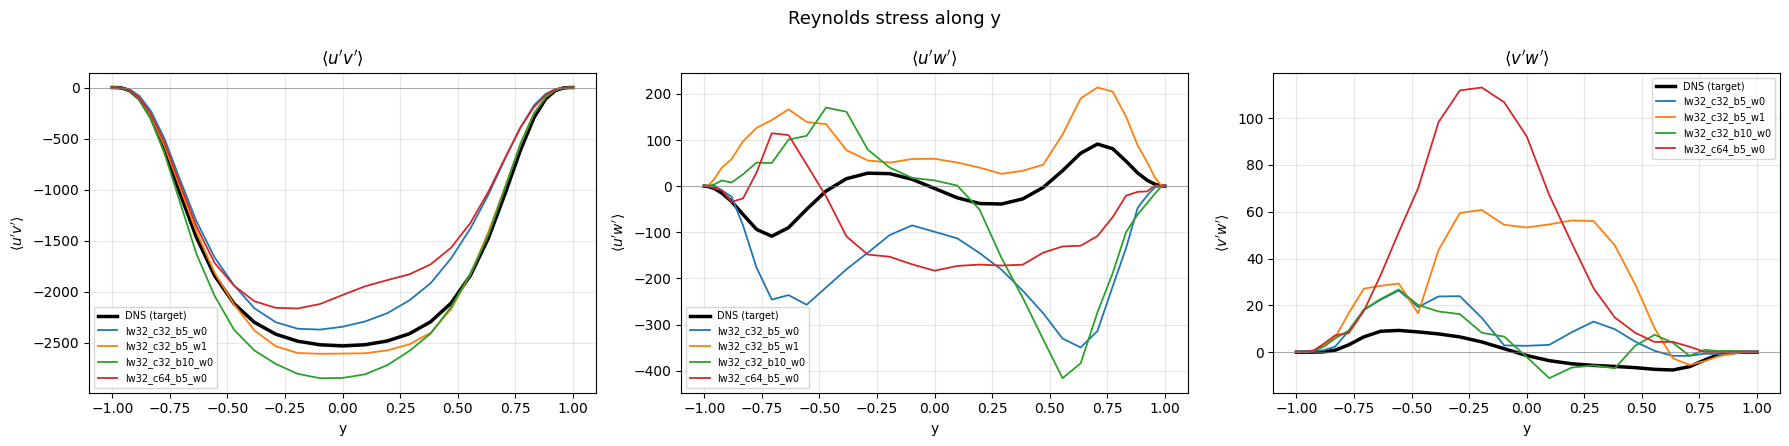

In [6]:
# =========================================================================
# RMS fluctuations & Reynolds stress — DNS + each model
# =========================================================================
def rms_and_reynolds(field):
    u_fluc = field - field.mean(axis=(0, 2, 4), keepdims=True)
    rms = np.sqrt((u_fluc ** 2).mean(axis=(0, 2, 4)))
    R = np.einsum("n c i y z, n d i y z -> c d y", u_fluc, u_fluc)
    return rms, R

rms_t, R_t = rms_and_reynolds(target_phys)

# per-model
rms_m, R_m = {}, {}
for name in model_names:
    rms_m[name], R_m[name] = rms_and_reynolds(models[name]["pred_phys"])

# --- RMS ---
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
fig.suptitle("Velocity fluctuation RMS along y", fontsize=13)
for c, lab in enumerate(comp_labels):
    ax = axes[c]
    ax.plot(y, rms_t[c], DNS_COLOR, lw=2.5, label='DNS (target)')
    for name in model_names:
        ax.plot(y, rms_m[name][c], color=MODEL_COLORS[name], lw=1.3, label=name)
    ax.set_title(f'{lab}'); ax.set_xlabel('y'); ax.set_ylabel('RMS')
    ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# --- Reynolds stress ---
stress_pairs = [(0, 1, r"$\langle u'v'\rangle$"), (0, 2, r"$\langle u'w'\rangle$"), (1, 2, r"$\langle v'w'\rangle$")]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
fig.suptitle("Reynolds stress along y", fontsize=13)
for ax, (i, j, lab) in zip(axes, stress_pairs):
    ax.plot(y, R_t[i, j], DNS_COLOR, lw=2.5, label='DNS (target)')
    for name in model_names:
        ax.plot(y, R_m[name][i, j], color=MODEL_COLORS[name], lw=1.3, label=name)
    ax.set_title(lab); ax.set_xlabel('y'); ax.set_ylabel(lab)
    ax.axhline(0, color='gray', lw=0.8, alpha=0.6)
    ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# --- summary table ---
print("max |profile - DNS| per model:")
for name in model_names:
    rms_dev = np.abs(rms_m[name] - rms_t).max()
    R_dev = np.abs(R_m[name][:3, :3] - R_t[:3, :3]).max()
    print(f"  {name:>18}: maxΔRMS={rms_dev:.3e}   maxΔRstress={R_dev:.3e}")


skewness / kurtosis(excess) at channel center (y=0.00):
  u_x: DNS skew=+0.000 kurt=-0.087 | lw32_c32_b5_w0 skew=+0.052 kurt=-0.154  lw32_c32_b5_w1 skew=-0.045 kurt=-0.187  lw32_c32_b10_w0 skew=-0.026 kurt=-0.209  lw32_c64_b5_w0 skew=-0.075 kurt=-0.184
  u_y: DNS skew=-0.002 kurt=-0.080 | lw32_c32_b5_w0 skew=+0.170 kurt=-0.351  lw32_c32_b5_w1 skew=+0.043 kurt=-0.345  lw32_c32_b10_w0 skew=+0.028 kurt=-0.145  lw32_c64_b5_w0 skew=+0.118 kurt=-0.691
  u_z: DNS skew=-0.004 kurt=+1.410 | lw32_c32_b5_w0 skew=-0.188 kurt=+1.358  lw32_c32_b5_w1 skew=-0.039 kurt=+1.050  lw32_c32_b10_w0 skew=+0.006 kurt=+1.631  lw32_c64_b5_w0 skew=-0.069 kurt=+1.132


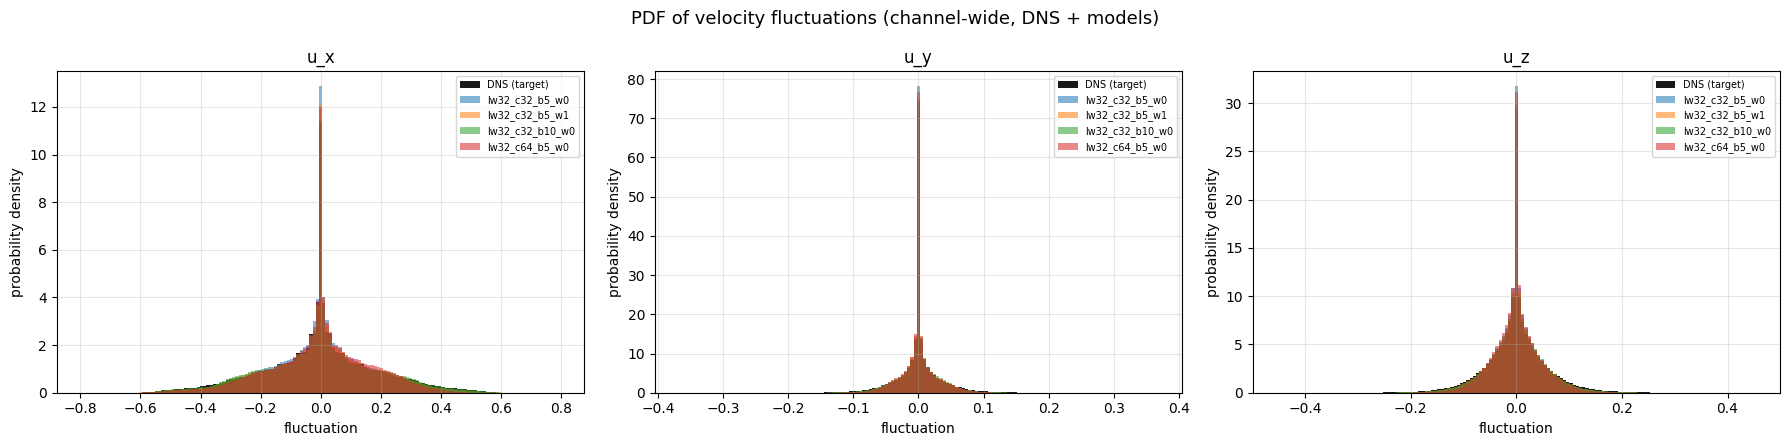

In [7]:
# =========================================================================
# PDF of velocity fluctuations — DNS + each model (channel-wide)
# =========================================================================
def fluct(field):
    return field - field.mean(axis=(0, 2, 4), keepdims=True)

u_fluc_t = fluct(target_phys)
u_fluc_m = {name: fluct(models[name]["pred_phys"]) for name in model_names}

# shared x-limits across models for fair comparison
def comp_limits(c):
    vals = [np.abs(u_fluc_t[:, c]).max()] + [np.abs(u_fluc_m[n][:, c]).max() for n in model_names]
    return max(vals) * 1.05

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
fig.suptitle("PDF of velocity fluctuations (channel-wide, DNS + models)", fontsize=13)
for c, lab in enumerate(comp_labels):
    ax = axes[c]
    lim = comp_limits(c)
    bins = np.linspace(-lim, lim, 150)
    ax.hist(u_fluc_t[:, c].ravel(), bins=bins, density=True, color=DNS_COLOR, alpha=0.9, label='DNS (target)')
    for name in model_names:
        ax.hist(u_fluc_m[name][:, c].ravel(), bins=bins, density=True, color=MODEL_COLORS[name], alpha=0.55, label=name)
    ax.set_title(f'{lab}'); ax.set_xlabel('fluctuation'); ax.set_ylabel('probability density')
    ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# --- skewness / kurtosis table ---
from scipy.stats import skew, kurtosis
print("skewness / kurtosis(excess) at channel center (y=%.2f):" % y[nyy // 2])
yc = nyy // 2
for c, lab in enumerate(comp_labels):
    vt = u_fluc_t[:, c, :, yc, :].ravel()
    base = f"  {lab}: DNS skew={skew(vt):+.3f} kurt={kurtosis(vt):+.3f} | "
    row = "  ".join(
        f"{name} skew={skew(u_fluc_m[name][:, c, :, yc, :].ravel()):+.3f} kurt={kurtosis(u_fluc_m[name][:, c, :, yc, :].ravel()):+.3f}"
        for name in model_names)
    print(base + row)
